# 02 — Résultats du modèle et explications (SHAP)

Ce notebook **présente** les résultats ; il ne réentraîne rien et ne réévalue pas le test.

1. Résultats de la modélisation (lus dans `reports/`, produits par `python tasks.py train`
   et `python tasks.py evaluate-test`).
2. Explications **globales** (SHAP, sur la validation) : quelles variables pèsent le plus.
3. Explications **locales** : pourquoi un client donné est jugé à risque. Les exemples
   utilisent des **clients fictifs** : on n'affiche pas de lignes réelles tant que la licence
   des données n'est pas confirmée. Pour un vrai client, en local :
   `python tasks.py explain --customer-id <ID>`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import Image, display

from churnguard.config import load_config, resolve_path
from churnguard.data import get_splits
from churnguard.explain import FEATURE_LABELS, ChurnExplainer, value_label
from churnguard.predict import load_model, predict

cfg = load_config()
REPORTS = resolve_path(cfg["paths"]["reports_dir"])
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#52514e"
pd.set_option("display.max_columns", 30)

## 1. Résultats de la modélisation

In [2]:
comparison = pd.read_csv(REPORTS / "model_comparison.csv")
cols = [
    "model",
    "strategy",
    "cv_pr_auc_mean",
    "cv_pr_auc_std",
    "val_threshold",
    "val_precision",
    "val_recall",
    "val_f1",
    "val_tp",
    "val_fp",
    "val_fn",
]
counts = ["val_tp", "val_fp", "val_fn"]
comparison.query("stage == 'C_validation'")[cols].round(3).astype(dict.fromkeys(counts, int))

,model,strategy,cv_pr_auc_mean,cv_pr_auc_std,val_threshold,val_precision,val_recall,val_f1,val_tp,val_fp,val_fn
12,logistic_regression,none,0.668,0.024,0.243,0.499,0.802,0.615,300,301,74
13,random_forest,none,0.675,0.012,0.271,0.508,0.802,0.622,300,291,74
14,xgboost,class_weight,0.677,0.015,0.489,0.508,0.805,0.623,301,292,73


Les trois modèles réglés sont **équivalents à un client près** sur la validation. La règle
fixée avant les résultats (meilleure précision à rappel ≥ 80 %) désigne le Random Forest ; elle
a été appliquée telle quelle.

In [3]:
artifact = load_model()
metadata = json.loads(resolve_path(cfg["model"]["metadata"]).read_text(encoding="utf-8"))
rows = {
    "validation": metadata["validation_metrics"],
    "test (évaluation unique)": metadata["test_metrics"],
}
summary = pd.DataFrame(
    {
        name: {k: m[k] for k in ["precision", "recall", "f1", "roc_auc", "pr_auc"]}
        | m["confusion_matrix"]
        for name, m in rows.items()
    }
).T
print(f"Modèle : {metadata['model']} — seuil {metadata['threshold']:.4f}")
print(f"Règle : {metadata['threshold_rule']}")
summary.round(3).astype(dict.fromkeys(["tn", "fp", "fn", "tp"], int))

Modèle : random_forest — seuil 0.2712
Règle : précision maximale parmi les seuils de rappel >= 80% (validation)


,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
validation,0.508,0.802,0.622,0.837,0.641,744,291,74,300
test (évaluation unique),0.514,0.802,0.626,0.844,0.653,751,284,74,300


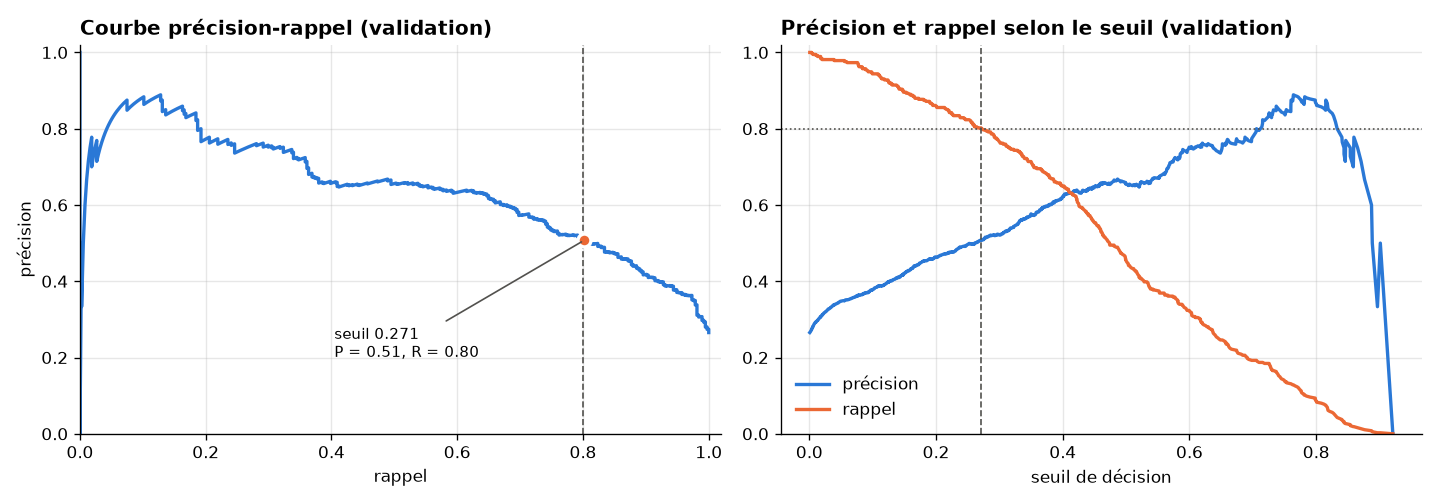

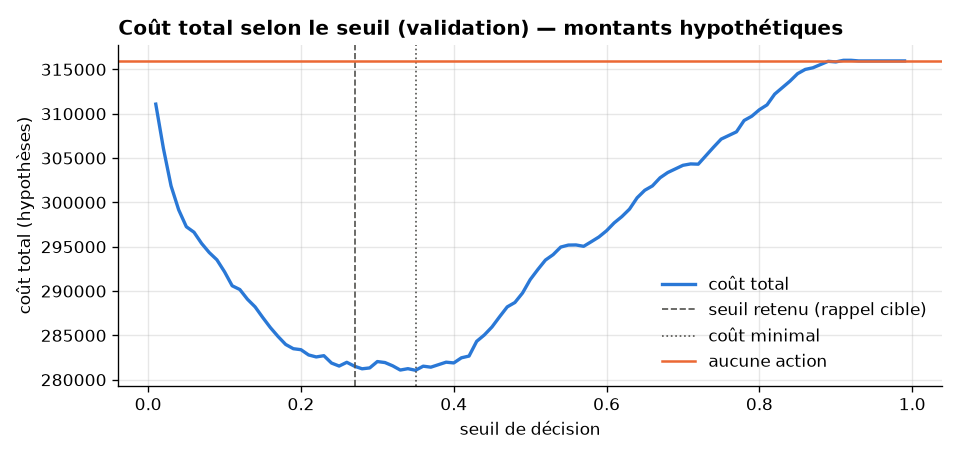

In [4]:
display(Image(REPORTS / "figures" / "threshold_validation.png"))
display(Image(REPORTS / "figures" / "cost_validation.png"))

> Le graphique de coût repose sur des **montants hypothétiques** (voir le README) ; il illustre
> l'intérêt d'un seuil adapté mais ne sert pas à le choisir.

## 2. Explications globales (SHAP, validation)

> **SHAP** répartit, pour chaque client, l'écart entre sa probabilité prédite et la probabilité
> moyenne entre les variables. Pour ce Random Forest, les contributions sont en **points de
> probabilité** et s'additionnent exactement : valeur de base + somme des contributions =
> probabilité du client. Les colonnes one-hot d'une même variable sont regroupées.

In [5]:
explainer = ChurnExplainer(artifact)
val = get_splits(cfg)["val"]
contrib = explainer.contributions(val)
proba = predict(artifact, val)["churn_probability"]
print(f"Valeur de base (probabilité moyenne vue par le modèle) : {explainer.base_value:.3f}")
gap = np.abs(explainer.base_value + contrib.sum(axis=1) - proba).max()
print(f"Erreur d'additivité maximale : {gap:.1e}")

Valeur de base (probabilité moyenne vue par le modèle) : 0.265
Erreur d'additivité maximale : 2.7e-15


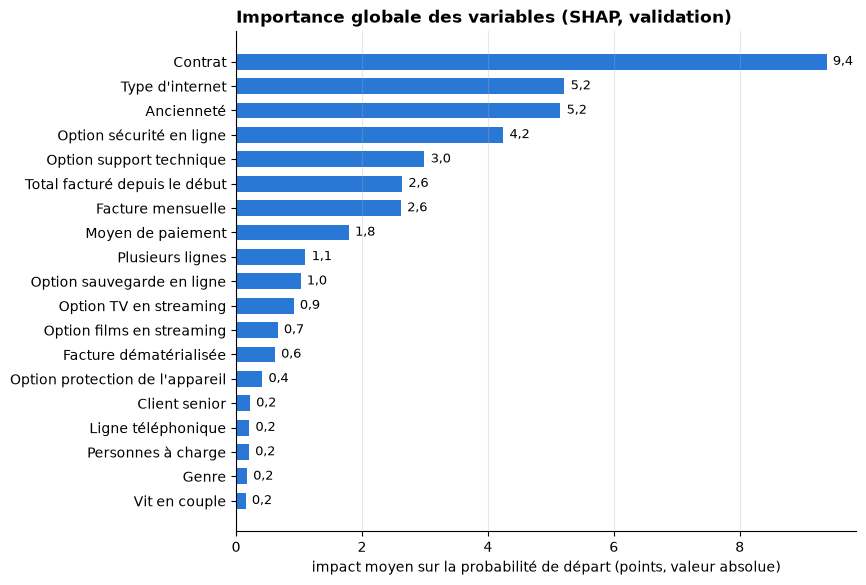

,feature,label,mean_abs_impact,mean_abs_points
0,Contract,Contrat,0.0938,9.3792
1,InternetService,Type d'internet,0.0521,5.2149
2,tenure,Ancienneté,0.0515,5.1511
3,OnlineSecurity,Option sécurité en ligne,0.0424,4.2433
4,TechSupport,Option support technique,0.0299,2.9910
5,TotalCharges,Total facturé depuis le début,0.0264,2.6370
6,MonthlyCharges,Facture mensuelle,0.0262,2.6184
7,PaymentMethod,Moyen de paiement,0.0179,1.7904
8,MultipleLines,Plusieurs lignes,0.0110,1.1021
9,OnlineBackup,Option sauvegarde en ligne,0.0102,1.0233


In [6]:
importance = explainer.global_importance(val)
data = importance.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(data["label"], data["mean_abs_points"], color=BLUE, height=0.65)
for y, v in enumerate(data["mean_abs_points"]):
    ax.text(v + 0.1, y, f"{v:.1f}".replace(".", ","), va="center", fontsize=9)
ax.set_xlabel("impact moyen sur la probabilité de départ (points, valeur absolue)")
ax.set_title("Importance globale des variables (SHAP, validation)", loc="left", fontweight="bold")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
importance.round(4)

L'importance globale dit **combien** une variable pèse en moyenne, pas **dans quel sens**.
Le graphique « beeswarm » ci-dessous montre le sens : chaque point est un client de la
validation, sa position est la contribution de la variable (à droite = augmente le risque), et
sa couleur la valeur de la variable (rouge = élevée ; pour une modalité one-hot, rouge = le
client a cette modalité).

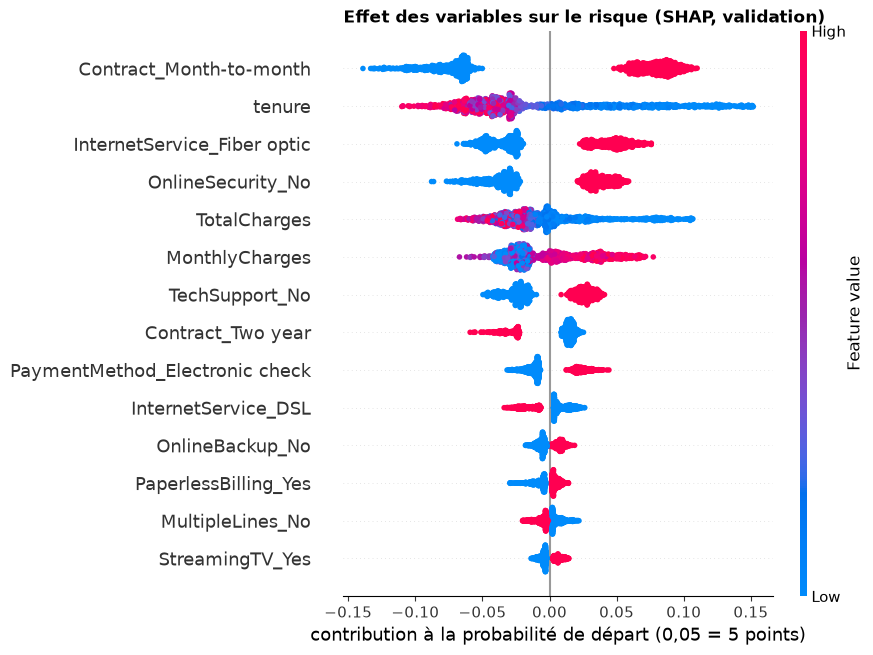

In [7]:
pre = artifact["pipeline"].named_steps["preprocess"]
features = artifact["numeric_features"] + artifact["categorical_features"]
X_val_t = pd.DataFrame(pre.transform(val[features]), columns=pre.get_feature_names_out())
# Pour la couleur, on montre les valeurs numériques d'origine (non normalisées).
for col in artifact["numeric_features"]:
    X_val_t[col] = val[col].to_numpy()
shap_t = explainer.transformed_shap_values(val)
shap.summary_plot(shap_t, X_val_t, max_display=14, show=False, plot_size=(9, 6.5))
plt.title("Effet des variables sur le risque (SHAP, validation)", loc="left", fontweight="bold")
plt.gca().set_xlabel("contribution à la probabilité de départ (0,05 = 5 points)")
plt.show()

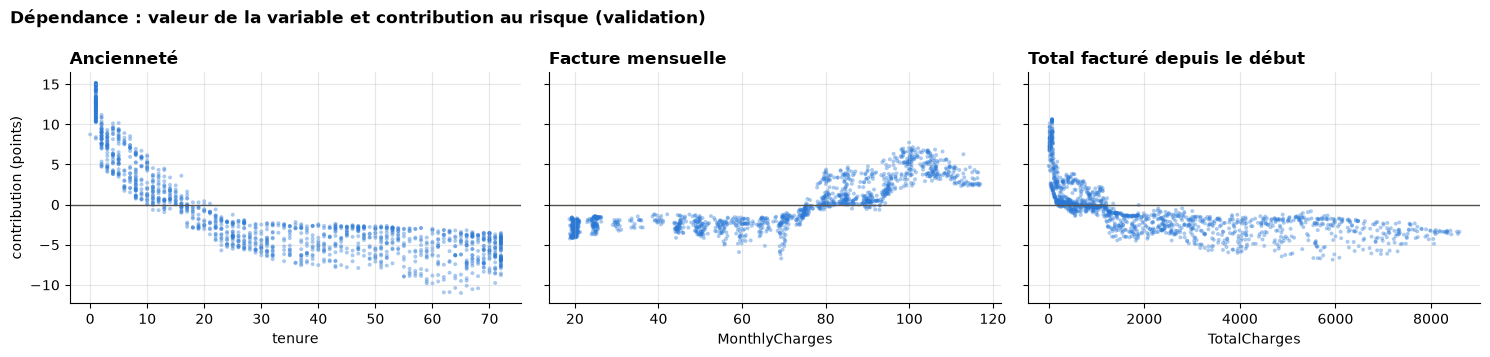

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, col in zip(axes, artifact["numeric_features"], strict=True):
    ax.scatter(val[col], 100 * contrib[col], s=8, alpha=0.4, color=BLUE, edgecolor="none")
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_title(FEATURE_LABELS[col], loc="left", fontweight="bold")
    ax.set_xlabel(col)
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("contribution (points)")
fig.suptitle(
    "Dépendance : valeur de la variable et contribution au risque (validation)",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()
plt.show()

## 3. Explications locales : trois clients fictifs

In [9]:
fictifs = pd.DataFrame(
    [
        {
            "customerID": "FICTIF-A",
            "gender": "Female",
            "SeniorCitizen": "No",
            "Partner": "No",
            "Dependents": "No",
            "tenure": 2,
            "PhoneService": "Yes",
            "MultipleLines": "No",
            "InternetService": "Fiber optic",
            "OnlineSecurity": "No",
            "OnlineBackup": "No",
            "DeviceProtection": "No",
            "TechSupport": "No",
            "StreamingTV": "Yes",
            "StreamingMovies": "No",
            "Contract": "Month-to-month",
            "PaperlessBilling": "Yes",
            "PaymentMethod": "Electronic check",
            "MonthlyCharges": 85.5,
            "TotalCharges": 171.0,
        },
        {
            "customerID": "FICTIF-B",
            "gender": "Male",
            "SeniorCitizen": "No",
            "Partner": "Yes",
            "Dependents": "No",
            "tenure": 18,
            "PhoneService": "Yes",
            "MultipleLines": "Yes",
            "InternetService": "DSL",
            "OnlineSecurity": "Yes",
            "OnlineBackup": "No",
            "DeviceProtection": "No",
            "TechSupport": "No",
            "StreamingTV": "No",
            "StreamingMovies": "No",
            "Contract": "Month-to-month",
            "PaperlessBilling": "No",
            "PaymentMethod": "Mailed check",
            "MonthlyCharges": 60.2,
            "TotalCharges": 1083.6,
        },
        {
            "customerID": "FICTIF-C",
            "gender": "Female",
            "SeniorCitizen": "No",
            "Partner": "Yes",
            "Dependents": "Yes",
            "tenure": 60,
            "PhoneService": "Yes",
            "MultipleLines": "Yes",
            "InternetService": "DSL",
            "OnlineSecurity": "Yes",
            "OnlineBackup": "Yes",
            "DeviceProtection": "Yes",
            "TechSupport": "Yes",
            "StreamingTV": "No",
            "StreamingMovies": "No",
            "Contract": "Two year",
            "PaperlessBilling": "No",
            "PaymentMethod": "Credit card (automatic)",
            "MonthlyCharges": 75.0,
            "TotalCharges": 4500.0,
        },
    ]
).set_index("customerID")
predictions = predict(artifact, fictifs)
predictions["churn_probability"] = predictions["churn_probability"].round(3)
print(f"Seuil de décision : {artifact['threshold']:.4f}")
predictions

Seuil de décision : 0.2712


,churn_probability,churn_predicted
customerID,,
FICTIF-A,0.757,True
FICTIF-B,0.185,False
FICTIF-C,0.024,False


In [10]:
for client_id in fictifs.index:
    p = predictions.loc[client_id, "churn_probability"]
    print(
        f"{client_id} — probabilité {100 * p:.1f} %"
        f" -> {'signalé' if predictions.loc[client_id, 'churn_predicted'] else 'non signalé'}"
    )
    for i, f in enumerate(explainer.top_factors(fictifs.loc[[client_id]]), 1):
        print(f"  {i}. {f['text']}")
    print()

FICTIF-A — probabilité 75.7 % -> signalé
  1. Contrat : au mois — augmente le risque (+11,6 points)
  2. Ancienneté : 2 mois — augmente le risque (+9,2 points)
  3. Type d'internet : fibre optique — augmente le risque (+7,2 points)
  4. Option sécurité en ligne : non — augmente le risque (+5,8 points)
  5. Total facturé depuis le début : 171,00 — augmente le risque (+4,2 points)

FICTIF-B — probabilité 18.5 % -> non signalé
  1. Contrat : au mois — augmente le risque (+7,7 points)
  2. Type d'internet : ADSL — diminue le risque (−6,9 points)
  3. Option sécurité en ligne : oui — diminue le risque (−4,0 points)
  4. Facture mensuelle : 60,20 — diminue le risque (−3,1 points)
  5. Option support technique : non — augmente le risque (+2,5 points)

FICTIF-C — probabilité 2.4 % -> non signalé
  1. Contrat : deux ans — diminue le risque (−9,1 points)
  2. Ancienneté : 60 mois — diminue le risque (−3,8 points)
  3. Type d'internet : ADSL — diminue le risque (−2,8 points)
  4. Option sécurité 

Le graphique « waterfall » part de la probabilité moyenne (valeur de base, en bas) et ajoute
la contribution de chaque variable jusqu'à la probabilité du client (en haut). Les valeurs
sont en probabilité : +0,12 = +12 points.

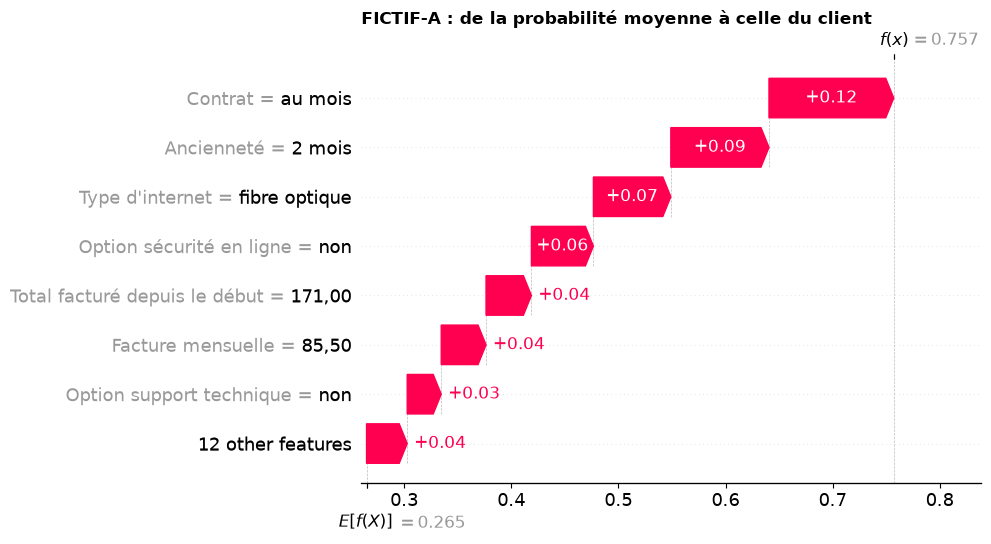

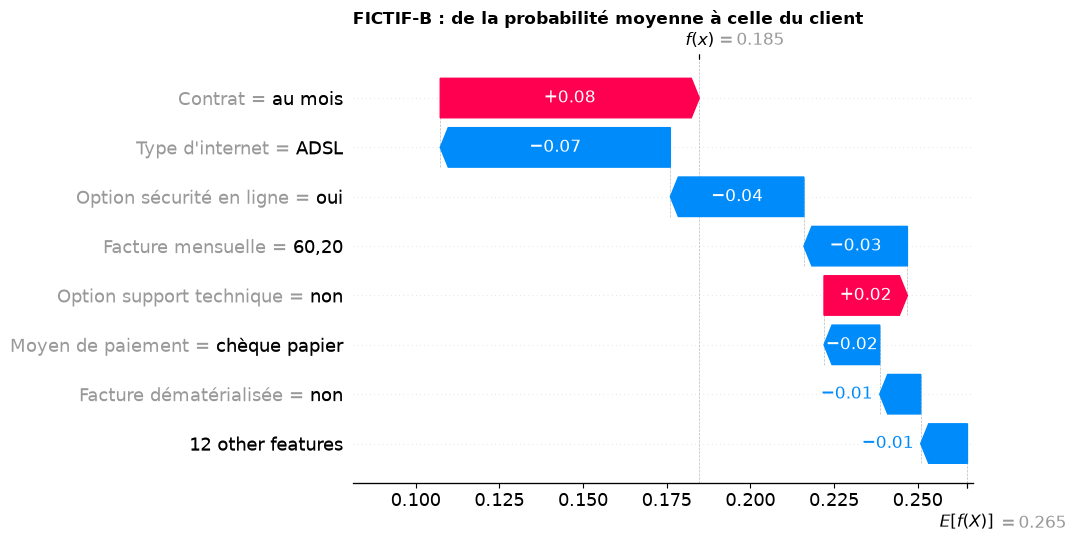

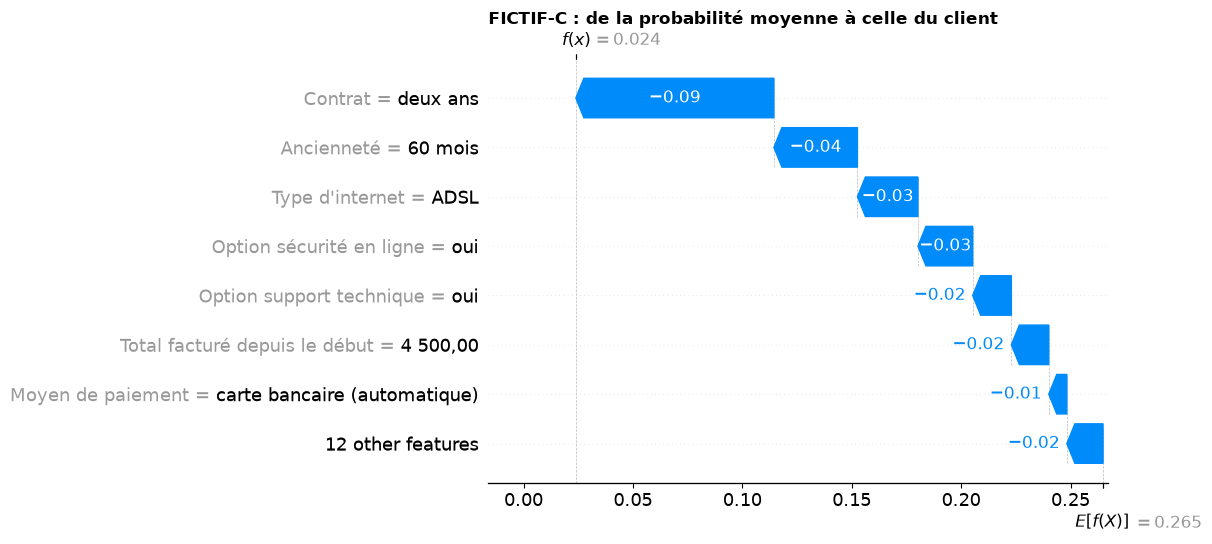

In [11]:
def waterfall(client_id: str, max_display: int = 8) -> None:
    row = fictifs.loc[[client_id]]
    c = explainer.contributions(row).iloc[0]
    names = [f"{FEATURE_LABELS[f]} = {value_label(f, row.iloc[0][f])}" for f in c.index]
    expl = shap.Explanation(
        values=c.to_numpy(), base_values=explainer.base_value, feature_names=names
    )
    shap.plots.waterfall(expl, max_display=max_display, show=False)
    plt.title(
        f"{client_id} : de la probabilité moyenne à celle du client", loc="left", fontweight="bold"
    )
    plt.show()


for client_id in fictifs.index:
    waterfall(client_id)

## 4. Limites de ces explications

- **SHAP explique le modèle, pas la réalité** : une contribution positive du contrat mensuel
  signifie que le modèle associe ce contrat à plus de départs, pas que le contrat *cause* le
  départ.
- **Variables corrélées** : `tenure` et `TotalCharges` sont très liées (Spearman 0,90 sur le
  train) ; le modèle peut répartir leur effet entre les deux de façon arbitraire. Il faut les
  lire ensemble.
- **Valeur de base** : les contributions sont relatives à la probabilité moyenne vue par le
  modèle sur son train (≈ taux de départ), pas à un « client idéal ».
- Les explications ne sont exactes qu'en points de probabilité **pour ce type de modèle**
  (Random Forest) ; un autre modèle demanderait une autre approche.

## 5. Conclusions

Constats (validation, 1 409 clients ; contributions en points de probabilité) :

- **Le contrat domine** : 9,4 points d'impact moyen. En moyenne, le contrat au mois ajoute
  9,8 points au risque, le contrat d'un an en retire 7,0 et celui de deux ans 10,6.
- Viennent ensuite le **type d'internet** (5,2), l'**ancienneté** (5,2), les options
  **sécurité en ligne** (4,2) et **support technique** (3,0), puis les montants (2,6 chacun).
- **Ancienneté** : +9,2 points en moyenne pendant les 6 premiers mois, autour de 0 entre 12 et
  18 mois, puis de −2,5 à −5,7 points au-delà de 18 mois.
- **Facture mensuelle** : elle diminue le risque sous 70 (environ −2,5 points) et l'augmente
  au-delà de 80 (+1,4 à +4,5 points selon la tranche).
- **Moyen de paiement** : le chèque électronique ajoute 2,6 points en moyenne, les autres moyens
  en retirent 1,2 à 1,4. L'effet est plus modeste que l'écart brut de taux de départ vu dans
  l'exploration (46 % contre 15 %) : une hypothèse est qu'une partie de cet écart est déjà
  portée par des variables liées (contrat, ancienneté), non vérifiée ici.
- Les variables **démographiques** (genre, couple, senior, personnes à charge) et la ligne
  téléphonique pèsent moins de 0,3 point en moyenne.
- Ces résultats rejoignent l'exploration du notebook 01 (contrat, ancienneté, fibre, options de
  protection), ce qui rend le modèle cohérent et explicable à un public métier.

Les explications des trois clients fictifs montrent le format livré par
`ChurnExplainer.top_factors` : les 5 facteurs les plus importants, dans les deux sens, avec
l'impact en points de probabilité. C'est le format renvoyé par l'API (`POST /predict`).